# Global Solution – CitizenTech: apoio ao pequeno produtor rural

**Grupo 12 · Fase 7 – Advanced Models and AI (FIAP ON)** · AgroPrevisao (soja, Paraná)

## 1. Título e descrição do problema

- **Cenário:** pequenos produtores de soja do Paraná decidem o plantio e a venda sem estimativa de safra.
- **Relevância:** a renda e a segurança alimentar das famílias dependem de prever bem a safra.
- **Impactados:** produtores de soja de cada município do Paraná.
- **Como os dados ajudam:** um modelo supervisionado estima o rendimento médio (kg/ha) de cada município no ano da safra, usando o histórico do próprio município, o clima da safra e a área cultivada. A estimativa serve de base para o planejamento.

## 2. Carregamento e descrição do dataset

- **Fontes:** IBGE/SIDRA (Produção Agrícola Municipal, tabela 1612) e INMET (estações automáticas do Paraná, dados horários, 2000 a 2025).
- **Preparação:** `ml/preparar_dados.py` gera `data/dataset_soja_pr.csv`, com uma linha por município e ano (2008 a 2024).
- **Variável-alvo:** `rendimento_kg_ha`, rendimento médio da produção em kg/ha.
- **Variáveis preditoras (todas conhecidas antes da colheita):**
  - `rend_media3`: média do rendimento dos três anos anteriores do mesmo município;
  - `rend_ultimo`: rendimento do ano anterior;
  - `area_anterior`: área colhida do ano anterior;
  - `precip_safra_mm` e `temp_media_safra_c`: clima da janela de outubro a abril (média das estações do estado);
  - `tendencia_ano`: anos desde 2008, para captar o ganho tecnológico.
- **Excluídas:** `area_colhida_ha` e `producao_t` do próprio ano, porque só são conhecidas depois da colheita e vazariam a resposta.
- **Limitação:** o clima é do estado, porque o IBGE não traz coordenadas dos municípios.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import os
caminho = '../data/dataset_soja_pr.csv' if os.path.exists('../data/dataset_soja_pr.csv') else 'dataset_soja_pr.csv'
bruto = pd.read_csv(caminho)
print('linhas brutas:', bruto.shape)
bruto.head()

linhas brutas: (6367, 10)


,municipio_cod,municipio,ano,rendimento_kg_ha,area_colhida_ha,producao_t,precip_safra_mm,temp_media_safra_c,n_estacoes_clima,tendencia_ano
0,4100103,Abatiá - PR,2008,2600.0,5250.0,13650.0,1116.6,22.56,3,0
1,4100459,Altamira do Paraná - PR,2008,2749.0,823.0,2263.0,957.1,22.67,3,0
2,4100509,Altônia - PR,2008,2600.0,2000.0,5200.0,855.2,24.01,3,0
3,4100608,Alto Paraná - PR,2008,2400.0,150.0,360.0,947.4,23.87,3,0
4,4100707,Alto Piquiri - PR,2008,2701.0,16500.0,44568.0,866.2,23.84,3,0


## 3. Pré-processamento e variáveis de histórico

As variáveis de histórico usam **somente anos anteriores** ao da linha (`shift(1)`), para não haver vazamento de informação. Os primeiros três anos de cada município são descartados, porque não têm histórico suficiente.

In [2]:
df = bruto.sort_values(['municipio_cod', 'ano']).copy()
g = df.groupby('municipio_cod')

df['rend_ultimo'] = g['rendimento_kg_ha'].shift(1)
df['rend_media3'] = g['rendimento_kg_ha'].transform(lambda s: s.shift(1).rolling(3).mean())
df['area_anterior'] = g['area_colhida_ha'].shift(1)

features = ['rend_media3', 'rend_ultimo', 'area_anterior',
            'precip_safra_mm', 'temp_media_safra_c', 'tendencia_ano']
target = 'rendimento_kg_ha'

antes = len(df)
df = df.dropna(subset=features + [target]).copy()
print('linhas removidas por falta de histórico:', antes - len(df))
print('linhas finais:', len(df), '| anos', df['ano'].min(), '-', df['ano'].max())
print(df[features + [target]].isna().sum().sum(), 'valores ausentes restantes')

linhas removidas por falta de histórico: 1169
linhas finais: 5198 | anos 2011 - 2024
0 valores ausentes restantes


## 4. Divisão em treino e teste

Divisão **cronológica**: treino de 2011 a 2019 e teste de 2020 a 2024, como numa previsão real. A validação cruzada é feita só no treino, com dobras por ano.

In [3]:
train = df[df['ano'] <= 2019].copy()
test = df[df['ano'] >= 2020].copy()

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

print('treino:', X_train.shape, '| anos', train['ano'].min(), '-', train['ano'].max())
print('teste: ', X_test.shape, '| anos', test['ano'].min(), '-', test['ano'].max())

treino: (3287, 6) | anos 2011 - 2019
teste:  (1911, 6) | anos 2020 - 2024


## 5. Modelo de referência (linha de base)

Antes de treinar, medimos a previsão mais simples possível: usar a média histórica do município (`rend_media3`). Um modelo só tem valor se superar essa referência.

In [4]:
modelos = {
    'Referência (média histórica)': None,
    'Regressão Linear': make_pipeline(StandardScaler(), LinearRegression()),
    'Random Forest': RandomForestRegressor(n_estimators=400, min_samples_leaf=5,
                                           max_features=0.7, random_state=42),
}

gkf = GroupKFold(n_splits=5)
for nome, modelo in modelos.items():
    if modelo is None:
        continue
    s = cross_val_score(modelo, X_train, y_train, groups=train['ano'], cv=gkf,
                        scoring='neg_root_mean_squared_error')
    print(f'{nome}: RMSE validação cruzada (treino) = {-s.mean():.1f} ± {s.std():.1f} kg/ha')

Regressão Linear: RMSE validação cruzada (treino) = 625.2 ± 125.1 kg/ha


Random Forest: RMSE validação cruzada (treino) = 752.9 ± 131.4 kg/ha


## 6. Treino final e avaliação no teste (2020–2024)

In [5]:
resultados = []
preds = {}
for nome, modelo in modelos.items():
    if modelo is None:
        p = X_test['rend_media3'].values
    else:
        modelo.fit(X_train, y_train)
        p = modelo.predict(X_test)
    preds[nome] = p
    resultados.append({
        'modelo': nome,
        'RMSE (kg/ha)': np.sqrt(mean_squared_error(y_test, p)),
        'MAE (kg/ha)': mean_absolute_error(y_test, p),
        'R²': r2_score(y_test, p),
    })

tabela = pd.DataFrame(resultados).set_index('modelo').round(3)
tabela

,RMSE (kg/ha),MAE (kg/ha),R²
modelo,,,
Referência (média histórica),852.712,583.822,0.067
Regressão Linear,796.209,570.492,0.187
Random Forest,830.527,663.517,0.115


## 7. Visualizações explicativas

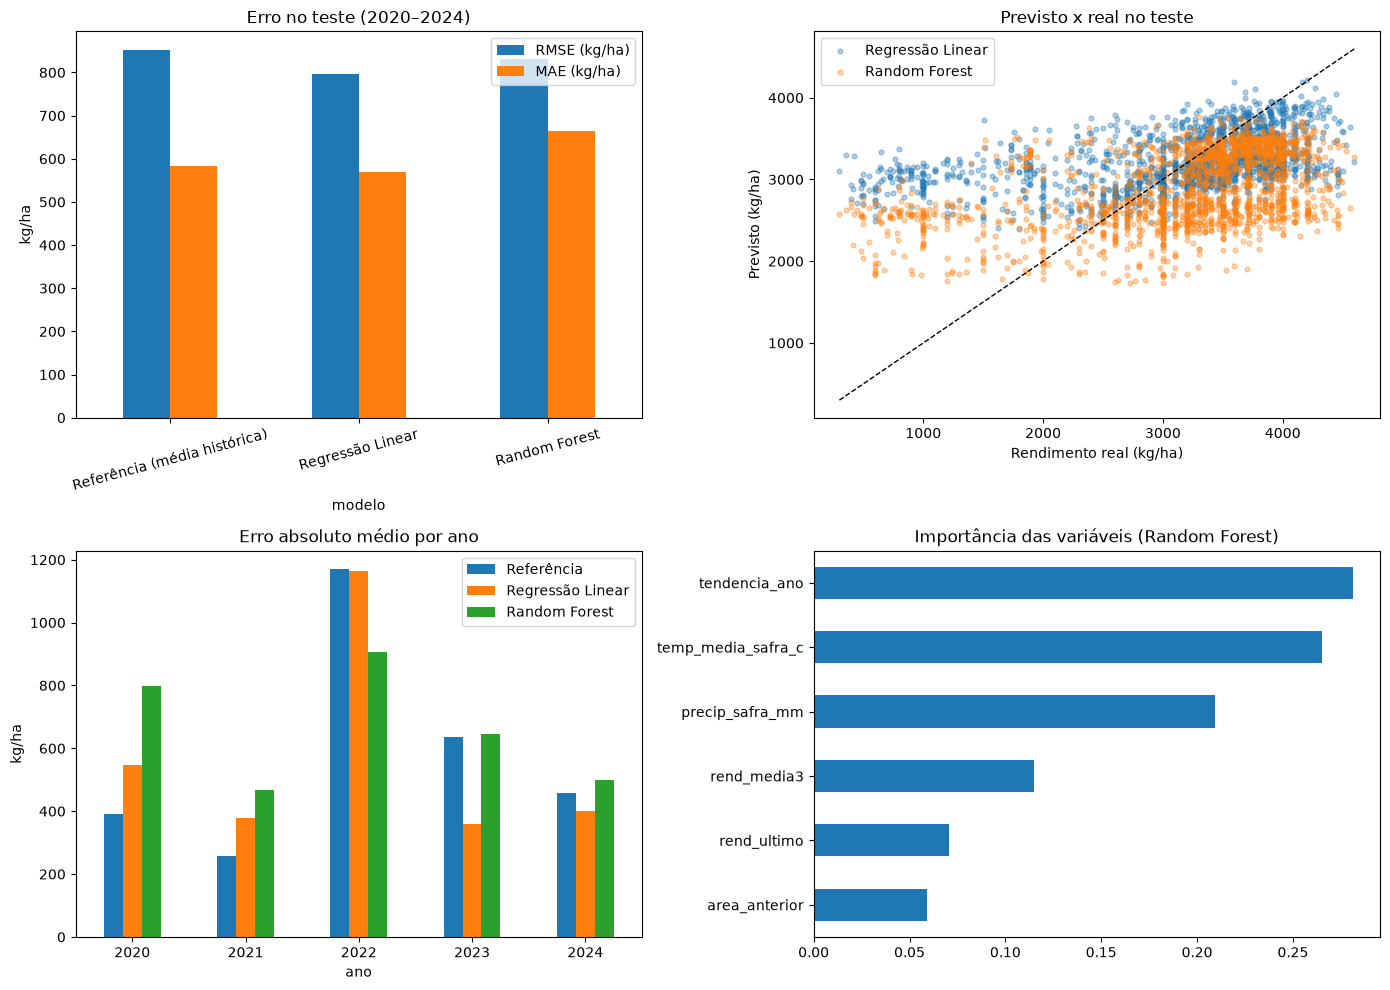

In [6]:
fig, eixos = plt.subplots(2, 2, figsize=(14, 10))

# (a) erro no teste
tabela[['RMSE (kg/ha)', 'MAE (kg/ha)']].plot.bar(ax=eixos[0, 0], rot=15)
eixos[0, 0].set_title('Erro no teste (2020–2024)')
eixos[0, 0].set_ylabel('kg/ha')

# (b) previsto x real
for nome in ['Regressão Linear', 'Random Forest']:
    eixos[0, 1].scatter(y_test, preds[nome], alpha=0.35, s=12, label=nome)
lim = [y_test.min(), y_test.max()]
eixos[0, 1].plot(lim, lim, 'k--', lw=1)
eixos[0, 1].set_xlabel('Rendimento real (kg/ha)')
eixos[0, 1].set_ylabel('Previsto (kg/ha)')
eixos[0, 1].set_title('Previsto x real no teste')
eixos[0, 1].legend()

# (c) erro médio por ano no teste
erro_ano = pd.DataFrame({'ano': test['ano'].values,
                         'Referência': np.abs(preds['Referência (média histórica)'] - y_test.values),
                         'Regressão Linear': np.abs(preds['Regressão Linear'] - y_test.values),
                         'Random Forest': np.abs(preds['Random Forest'] - y_test.values)})
erro_ano.groupby('ano').mean().plot.bar(ax=eixos[1, 0], rot=0)
eixos[1, 0].set_title('Erro absoluto médio por ano')
eixos[1, 0].set_ylabel('kg/ha')

# (d) importância das variáveis (Random Forest)
rf = modelos['Random Forest']
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot.barh(ax=eixos[1, 1])
eixos[1, 1].set_title('Importância das variáveis (Random Forest)')

plt.tight_layout()
plt.savefig('figuras_modelos.png', dpi=120)
plt.show()

## 8. Conclusão dos modelos

**Resultados no teste (2020–2024), anos que o modelo não viu no treino:**

| Modelo | RMSE (kg/ha) | MAE (kg/ha) | R² |
|---|---|---|---|
| Referência (média histórica) | 853 | 584 | 0,07 |
| Regressão Linear | **796** | **570** | **0,19** |
| Random Forest | 831 | 664 | 0,12 |

Na validação cruzada feita só no treino (2011–2019), a Regressão Linear também foi a melhor: RMSE de 625 ± 125 kg/ha, contra 753 ± 131 kg/ha da Random Forest.

**Escolha:** a **Regressão Linear**. Ela ficou na frente no teste em RMSE, MAE e R², e na validação cruzada. A Random Forest captou relações não lineares, mas errou mais no teste (principalmente no MAE), o que sugere que ela se ajustou ao treino sem generalizar bem.

**Leitura honesta:** o modelo escolhido supera a referência, mas o ganho é moderado: RMSE cerca de 7% menor e R² de 0,19. O erro médio (cerca de 570 kg/ha) ainda equivale a quase 19% do rendimento médio, de cerca de 3.050 kg/ha. Ele é útil como estimativa de apoio, mas não substitui a experiência do produtor.

**O que mais pesa no erro:** a seca de 2022 (rendimento mediano de cerca de 2.040 kg/ha) não foi prevista com precisão, e o teste tem apenas cinco anos. O clima agora é por município (média das três estações mais próximas), o que melhorou o modelo em relação à versão com clima do estado. Mesmo assim, há só 27 estações no Paraná, então parte dos municípios fica longe da estação que os representa.

## 9. Texto analítico

- **Escolhas de modelo:** a Regressão Linear foi escolhida por ser a mais estável na validação cruzada e a melhor no teste, e por ser fácil de explicar a produtores e gestores. A Random Forest foi testada como alternativa não linear e não superou a linear com estes dados.
- **Variáveis:** o histórico do próprio município (média dos três anos anteriores) é a principal informação. O clima da safra, a área do ano anterior e a tendência tecnológica completam o modelo. A área e a produção do próprio ano não entram, porque só são conhecidas após a colheita.
- **Limitações:** (1) apenas 27 estações meteorológicas no Paraná, com clima aproximado para municípios distantes delas; (2) o teste cobre apenas cinco anos; (3) não há medidas de solo, manejo, cultivar nem preço, que também influenciam o rendimento; (4) o histórico começa em 2008, quando a rede do INMET no estado passa a ter cobertura.
- **Vieses possíveis:** municípios pequenos e de agricultura familiar podem ter menos registros de produção e estar mais longe das estações, o que pode piorar a previsão justamente para os produtores que o projeto quer ajudar. Os dados do IBGE também refletem só a produção declarada.
- **Contribuição para a decisão:** a estimativa do modelo pode orientar o planejamento de plantio e a negociação de venda em conjunto com outras fontes (Conab, boletins de clima). Para uso prático, recomenda-se atualizar o modelo a cada safra e incluir dados locais de chuva e de solo.